# RAG Lab — Workshop 2 starter
*Build, break, decide.*

Work on your own. Run **Setup**, then the **Warm-up**, then the six-track **circuit**: A, B, C1, D1, D3, E (about 8 minutes each). Fill in the **scorecard** as you go.

Use Claude Code for the coding. The notebook's own model calls all go through **OpenRouter**: save your key as `OPENROUTER_API_KEY`, as an environment variable when running locally, or in Colab Secrets (the key icon on the left). Models whose ID ends in `:free` cost nothing; each account gets 20 requests a minute and 50 a day (1,000 a day after a one-off $10 credit purchase).

## 1. Setup

In [ ]:
%pip install -q openai langchain_huggingface sentence_transformers langchain_chroma chromadb langchain_text_splitters pypdf pandas

In [ ]:
import os, time, base64, io
from openai import OpenAI

def _secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

OPENROUTER_KEY = _secret("OPENROUTER_API_KEY")
if not OPENROUTER_KEY:
    raise RuntimeError("Set OPENROUTER_API_KEY (environment variable or Colab Secret), then re-run this cell.")
client = OpenAI(api_key=OPENROUTER_KEY, base_url="https://openrouter.ai/api/v1")

def list_free_models():
    """Current OpenRouter models whose ID ends in ':free' (the list changes often)."""
    return sorted(m.id for m in client.models.list().data if m.id.endswith(":free"))

FREE_MODELS = list_free_models()
preferred = [m for m in FREE_MODELS if any(k in m for k in ("gpt-oss", "llama-3.3-70b", "qwen", "deepseek", "gemma"))]
MODEL = (preferred or FREE_MODELS)[0]
print(f"{len(FREE_MODELS)} free models available; using {MODEL}.")

def free_model_capabilities():
    """Table of current :free models: whether each accepts images (Track C1) and supports tool calls (Track E)."""
    import json, urllib.request
    import pandas as pd
    req = urllib.request.Request("https://openrouter.ai/api/v1/models",
                                 headers={"Authorization": f"Bearer {OPENROUTER_KEY}"})
    data = json.load(urllib.request.urlopen(req, timeout=30))["data"]
    rows = [{"model": m["id"],
             "images": "image" in (m.get("architecture") or {}).get("input_modalities", []),
             "tools": "tools" in (m.get("supported_parameters") or []),
             "context_tokens": m.get("context_length")}
            for m in data if m["id"].endswith(":free")]
    return pd.DataFrame(rows).sort_values(["images", "tools"], ascending=False).reset_index(drop=True)

CAPS = free_model_capabilities()
IMAGE_MODELS = CAPS[CAPS.images].model.tolist()   # use one of these for Track C1 (and D2)
TOOL_MODELS = CAPS[CAPS.tools].model.tolist()     # use one of these for Track E
print(f"{len(IMAGE_MODELS)} free models accept images; {len(TOOL_MODELS)} support tool calls.")
display(CAPS.head(15))
print("Set MODEL to any ID above. Example for Track C1: ask_llm(..., images=[img], model=IMAGE_MODELS[0])")

USAGE = []   # one entry per call: model, input and output tokens

def _image_part(img):
    buf = io.BytesIO()
    img.convert("RGB").save(buf, format="PNG")
    return {"type": "image_url",
            "image_url": {"url": "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()}}

def ask_llm(prompt, system=None, model=None, images=None, max_tokens=800, temperature=0, retries=3):
    """Send one prompt (plus optional PIL images) to the chosen model and return its text answer."""
    content = [{"type": "text", "text": prompt}] + [_image_part(i) for i in (images or [])]
    messages = ([{"role": "system", "content": system}] if system else []) + \
               [{"role": "user", "content": content if images else prompt}]
    for attempt in range(retries):
        try:
            r = client.chat.completions.create(model=model or MODEL, messages=messages,
                                               max_tokens=max_tokens, temperature=temperature)
            u = r.usage
            USAGE.append({"model": model or MODEL,
                          "input_tokens": getattr(u, "prompt_tokens", None),
                          "output_tokens": getattr(u, "completion_tokens", None)})
            return r.choices[0].message.content
        except Exception as e:
            if "429" in str(e) and attempt < retries - 1:
                print("Rate limited; waiting 20 s..."); time.sleep(20); continue
            raise

print(ask_llm("In one short sentence, say which model you are."))
print(f"Model: {MODEL} | last call: {USAGE[-1]}")

### Shared corpus
Two documents from the original recipes: the 2022 State of the Union (plain prose, used in IBM's LangChain recipe) and the Midwest Food Bank 2020 annual report (text, tables, charts and photos, used in IBM's multimodal recipe). The PDF is read here as **plain text only**, on purpose.

In [ ]:
import urllib.request
from pypdf import PdfReader

SOTU_URL = "https://raw.githubusercontent.com/IBM/watson-machine-learning-samples/master/cloud/data/foundation_models/state_of_the_union.txt"
FOODBANK_URL = "https://web.archive.org/web/20230523232035if_/https://www.midwestfoodbank.org/images/AR_2020_WEB2.pdf"

for url, name in [(SOTU_URL, "state_of_the_union.txt"), (FOODBANK_URL, "foodbank_2020.pdf")]:
    if not os.path.exists(name):
        urllib.request.urlretrieve(url, name)

sotu_text = open("state_of_the_union.txt", encoding="utf-8").read()
foodbank_text = "\n".join(page.extract_text() or "" for page in PdfReader("foodbank_2020.pdf").pages)
DOCS = {"state_of_the_union.txt": sotu_text, "foodbank_2020.pdf": foodbank_text}
for name, text in DOCS.items():
    print(f"{name}: {len(text):,} characters")

### Classic RAG index
Granite embeddings (runs locally on CPU) and an in-memory Chroma vector store. Track A changes `CHUNK_SIZE`, `CHUNK_OVERLAP` and `TOP_K`.

In [ ]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from transformers import AutoTokenizer

EMBED_MODEL = "ibm-granite/granite-embedding-small-english-r2"
CHUNK_SIZE, CHUNK_OVERLAP, TOP_K = 256, 32, 4      # tokens, tokens, chunks

embeddings = HuggingFaceEmbeddings(model_name=EMBED_MODEL)
tokenizer = AutoTokenizer.from_pretrained(EMBED_MODEL)

def build_index(docs=None, chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP):
    """Chunk the documents, embed them, and return a fresh in-memory Chroma store."""
    splitter = RecursiveCharacterTextSplitter.from_huggingface_tokenizer(
        tokenizer, chunk_size=chunk_size, chunk_overlap=chunk_overlap)
    chunks = []
    for source, text in (docs or DOCS).items():
        for piece in splitter.split_text(text):
            chunks.append(Document(page_content=piece, metadata={"source": source, "chunk": len(chunks)}))
    db = Chroma(embedding_function=embeddings)
    db.add_documents(chunks)
    print(f"Indexed {len(chunks)} chunks (size {chunk_size}, overlap {chunk_overlap})")
    return db

vector_db = build_index()

## 2. Warm-up: the same question three ways

In [ ]:
import pandas as pd

QUESTIONS = [
    "What did the president say about Ketanji Brown Jackson?",
    "What did the speech propose on prescription drug costs?",
    "List every measure the speech proposed to fight inflation.",
    "How much was spent on food distribution relative to the amount of food distributed?",
    "What did the speech say about the 2024 Olympics?",
]

SYSTEM = ("Answer using only the provided context. Cite the context blocks you used, like [3]. "
          "If the context does not contain the answer, say so plainly.")

def format_context(docs):
    return "\n\n".join(f"[{d.metadata.get('chunk', i)}] ({d.metadata.get('source', '')})\n{d.page_content}"
                       for i, d in enumerate(docs))

def no_retrieval(q):
    return ask_llm(q), []

def long_context(q):
    ctx = "\n\n".join(f"=== {name} ===\n{text}" for name, text in DOCS.items())
    return ask_llm(f"Context:\n{ctx}\n\nQuestion: {q}", system=SYSTEM), []

def classic_rag(q, k=None, db=None):
    hits = (db or vector_db).similarity_search(q, k=k or TOP_K)
    return ask_llm(f"Context:\n{format_context(hits)}\n\nQuestion: {q}", system=SYSTEM), hits

WARMUP = {"no retrieval": no_retrieval, "long context": long_context, "classic RAG": classic_rag}

def compare(approaches, questions=QUESTIONS, pause=3):
    """Run each approach on each question. Every approach is a function q -> (answer, evidence)."""
    rows, evidence = [], {}
    for q in questions:
        for name, fn in approaches.items():
            answer, hits = fn(q)
            rows.append({"question": q[:60], "approach": name,
                         "input_tokens": USAGE[-1]["input_tokens"], "answer": answer})
            evidence[(q, name)] = hits
            time.sleep(pause)       # stay under OpenRouter's 20 requests a minute
    df = pd.DataFrame(rows)
    ALL_RUNS.append(df)          # every run is kept automatically for the wrap-up
    return df, evidence

ALL_RUNS = []
results, evidence = compare(WARMUP)
pd.set_option("display.max_colwidth", 400)
results

In [ ]:
# Evidence or it didn't happen: what did classic RAG actually retrieve?
q = QUESTIONS[2]
for d in evidence[(q, "classic RAG")]:
    print(f"--- chunk {d.metadata['chunk']} from {d.metadata['source']}\n{d.page_content[:500]}\n")

In [ ]:
# Input tokens per approach, summed and averaged over the 5 questions
results.groupby("approach")["input_tokens"].agg(["sum", "mean"]).round(0)

## 3. The circuit: six tracks, about 8 minutes each
Each track below has a short example and a diagram of the approach. For each one: make the decisions in the blue boxes, direct Claude Code to build it as a function `q -> (answer, evidence)`, then run it with `compare(...)`. Every run is recorded automatically, so there is nothing to fill in as you go. Leave `ask_llm()`, `QUESTIONS` and `compare()` unchanged so every result lines up with the warm-up.

To stay inside the free limit, cap per-chunk LLM calls at 20 (Track A) and per-image calls at 10 (Track C1).

### Track A: tune classic RAG

**Goal:** Get classic RAG to answer Q3 (the spread-out answer) without pasting in the whole document.

**In one line:** search by meaning *and* by keywords, then merge the two lists.

**Example** (illustration):

| Question: *"What is the warranty on part XK-220?"* | Top result |
| --- | --- |
| Vector search (meaning) | a general chunk about warranties |
| BM25 (keywords) | the chunk that mentions "XK-220" |
| Merged with RRF | the XK-220 chunk, because both lists rank it |

RRF score = sum of 1 / (60 + rank). Ranked 1st by BM25 and 4th by vectors: 1/61 + 1/64 = **0.032**. Ranked 2nd by vectors only: 1/62 = **0.016**.

**Good for:** exact names, numbers, codes. **Weak for:** answers spread across the whole document.

[Read more: Contextual Retrieval](https://www.anthropic.com/news/contextual-retrieval)

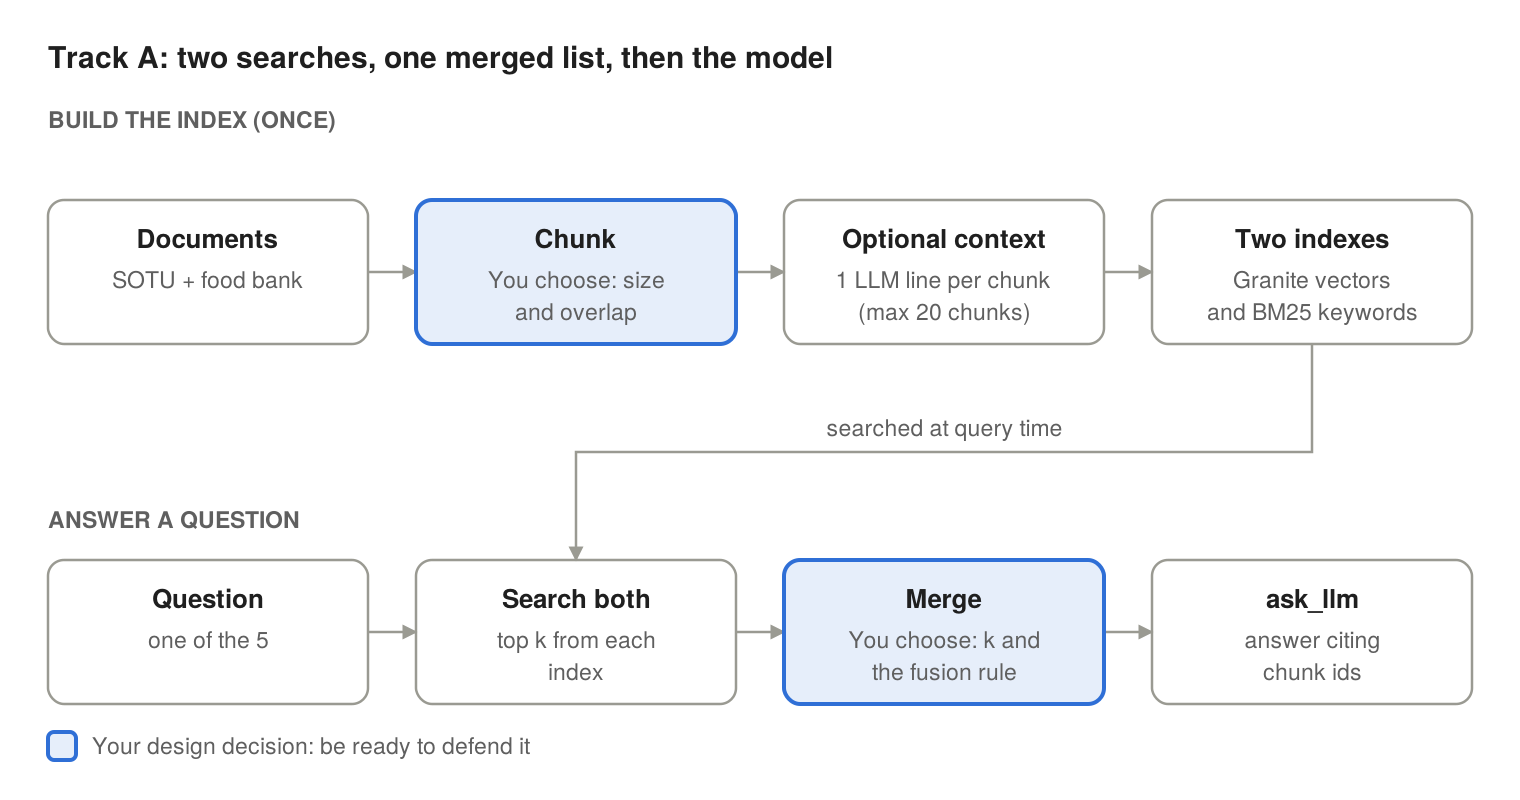

The blue boxes are your design decisions: make them, then direct Claude Code.

**Build**

- Sweep chunk size (128, 256, 512 tokens) and k (2, 4, 8) with `build_index(...)` and `classic_rag(q, k=..., db=...)`.
- Add BM25 keyword search (`pip install rank_bm25`) and merge it with the vector results.
- Stretch goal: contextual retrieval. Have the LLM write one sentence placing each chunk in its document, and embed that with the chunk (at most 20 chunks).

**Discussion point:** What happens when you ask about something mentioned in only one sentence, worded differently from the speech?

In [ ]:
def track_a(q):
    """Return (answer, evidence) for one question."""
    raise NotImplementedError("Build Track A here")

# When it works, run it on the 5 questions (recorded automatically):
# compare({"A tuned classic RAG": track_a})

### Track B: document-aware RAG

**Goal:** Show that how you parse a PDF matters as much as how you search it.

**In one line:** recover the PDF's structure before chunking, so tables and sections stay whole.

**Example** (the same table, made-up numbers):

Plain text extraction gives one flat line:

```
Region Meals Cost North 1200 3400 South 900 2100
```

Docling gives a table that keeps its headers:

| Region | Meals | Cost ($) |
| --- | --- | --- |
| North | 1,200 | 3,400 |
| South | 900 | 2,100 |

**Good for:** tables, reports, manuals. **Weak for:** plain prose; it's slow on CPU.

[Read more: Docling](https://docling-project.github.io/docling/)

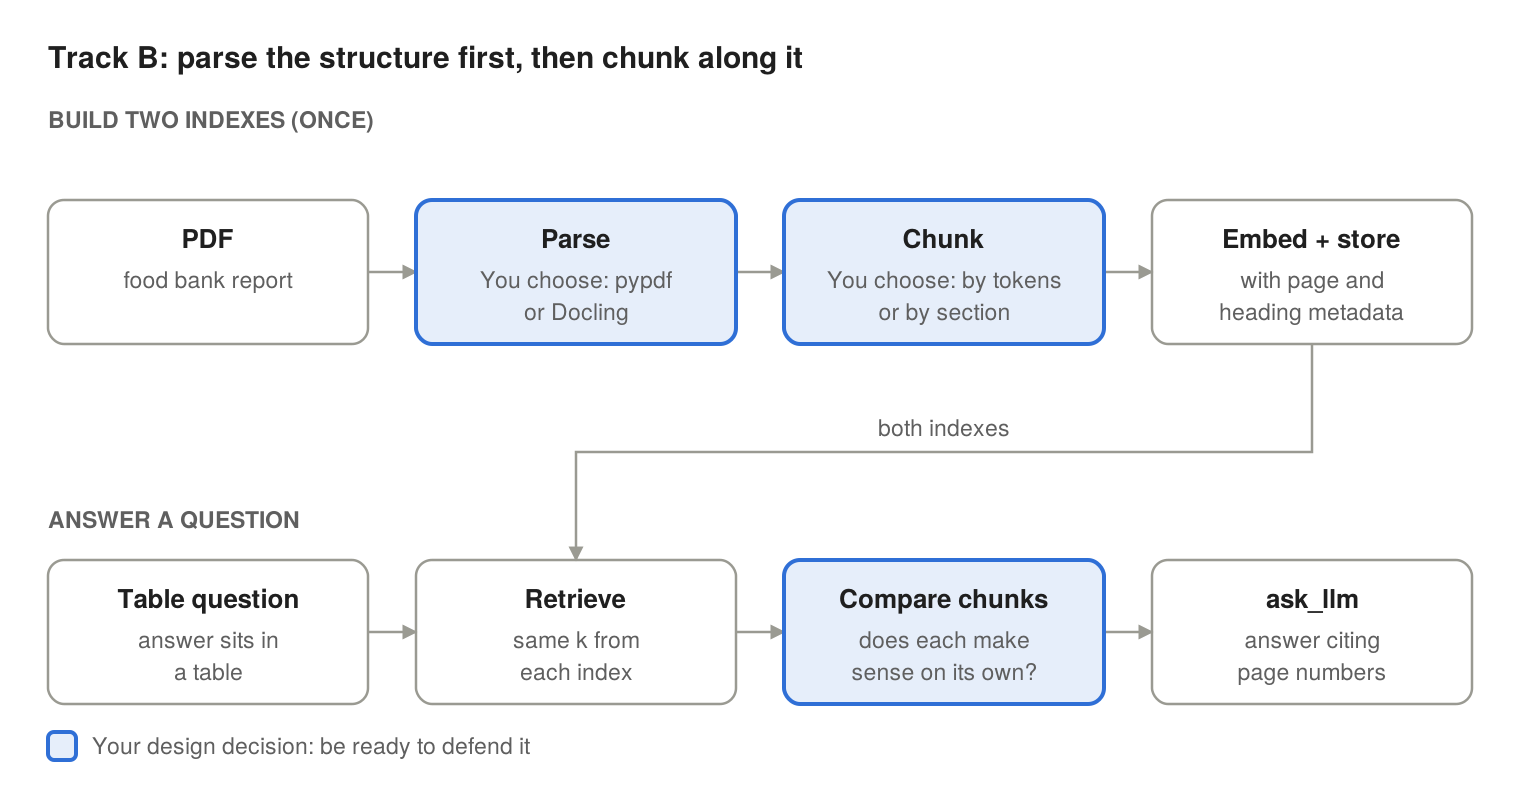

The blue boxes are your design decisions: make them, then direct Claude Code.

**Build**

- Index `foodbank_2020.pdf` twice: plain text (pypdf), and Docling with `HybridChunker` (tables exported as markdown). Use the first 10 pages if it is slow.
- Ask 3 questions whose answers sit in tables.
- Compare the retrieved chunks side by side.

**Discussion point:** What happens when the answer needs a table row plus the paragraph that explains it?

In [ ]:
def track_b(q):
    """Return (answer, evidence) for one question."""
    raise NotImplementedError("Build Track B here")

# When it works, run it on the 5 questions (recorded automatically):
# compare({"B document-aware": track_b})

### Track C1: caption, then embed

**Goal:** Answer Q4, whose answer is in a chart rather than the text.

**In one line:** a vision model describes each image, and the descriptions are searched like text.

**Example** (illustration):

| Step | What you have |
| --- | --- |
| Image in the PDF | a bar chart with no text around it |
| Caption from the vision model | "Bar chart of meals served per year: 2019 about 2.1M, 2020 about 2.9M" |
| Question | *"How many meals were served in 2020?"* now matches the caption |

**Good for:** charts and figures inside text documents. **Weak for:** anything the caption leaves out or misreads.

[Read more: IBM Multimodal RAG recipe](https://github.com/ibm-granite-community/granite-snack-cookbook/blob/main/recipes/RAG/Granite_Multimodal_RAG.ipynb)

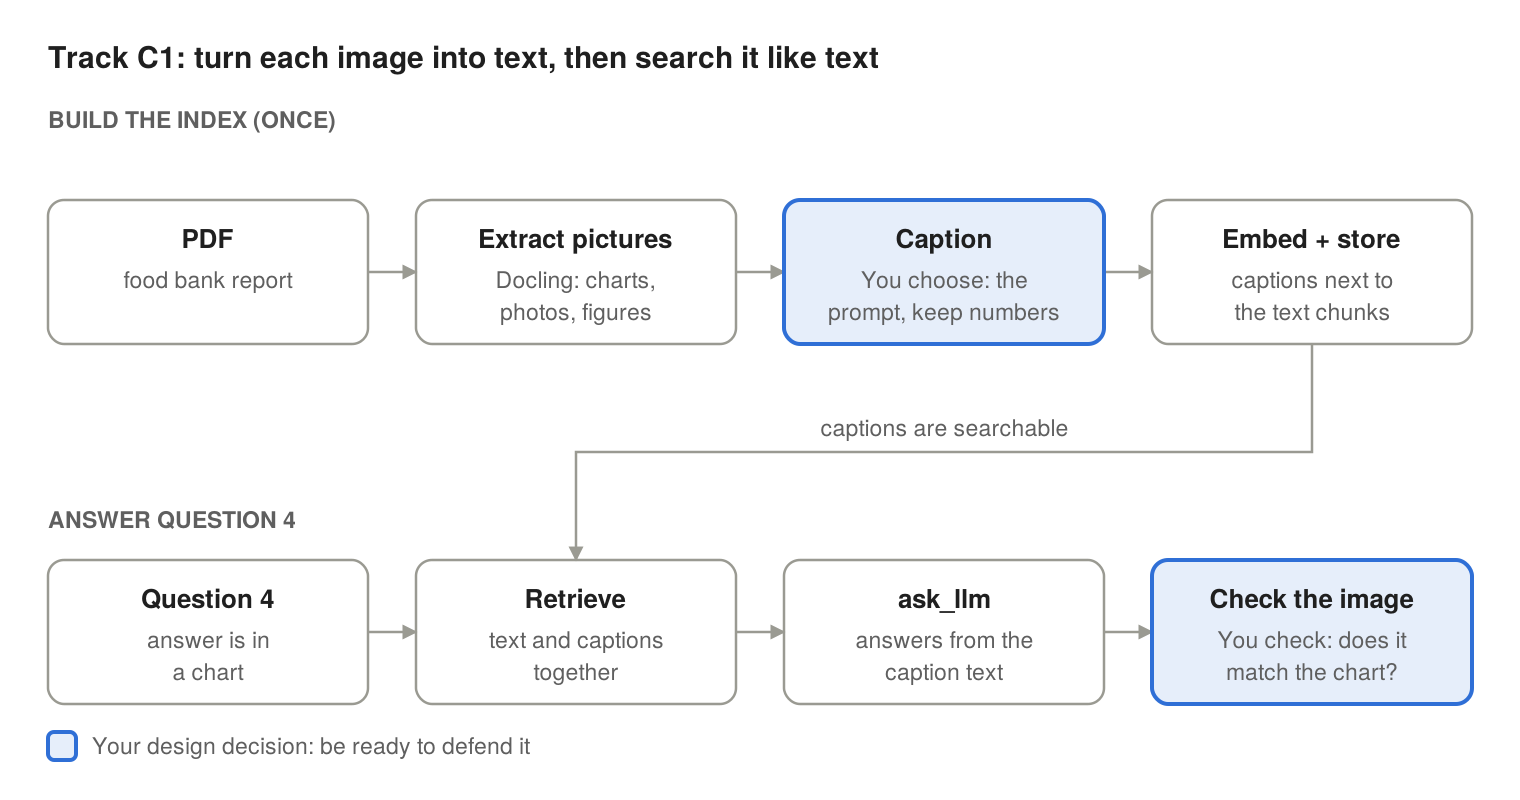

The blue boxes are your design decisions: make them, then direct Claude Code.

**Build**

- Extract the pictures with Docling (`generate_picture_images=True`).
- Caption up to 10 with `ask_llm(prompt, images=[img], model=...)` on an image-capable free model.
- Add the captions to the index and re-ask Q4. Open the image and check the caption against it.

**Discussion point:** What happens with a chart whose meaning depends on its axis labels? Does the description keep the numbers?

In [ ]:
def track_c1(q):
    """Return (answer, evidence) for one question."""
    raise NotImplementedError("Build Track C1 here")

# When it works, run it on the 5 questions (recorded automatically):
# compare({"C1 caption then embed": track_c1})

### Track D1: long context, done properly

**Goal:** Measure what skipping retrieval costs.

**In one line:** skip retrieval and send the whole corpus with every question, then work out what that costs.

**Example** (illustration, 500 questions a day):

| | Input tokens per question | Input tokens per day |
| --- | --- | --- |
| Long context, 20,000-token corpus | 20,000 | 10,000,000 |
| Classic RAG, 4 chunks | 1,000 | 500,000 |

**Good for:** small, stable corpora; answers spread throughout. **Weak for:** large corpora, many questions; details lost in the middle.

[Read more: Lost in the Middle](https://arxiv.org/abs/2307.03172)

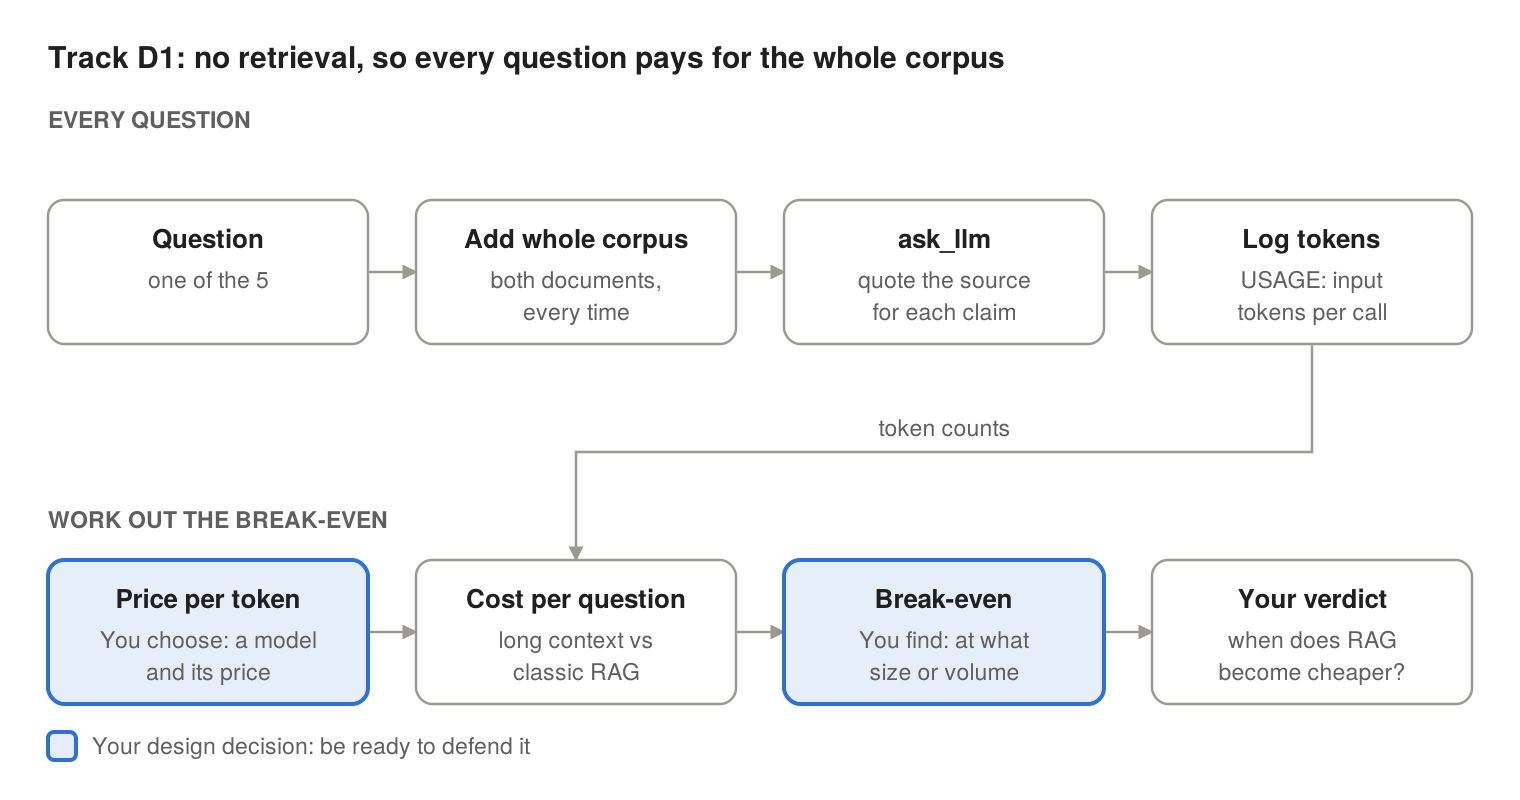

The blue boxes are your design decisions: make them, then direct Claude Code.

**Build**

- Run `long_context` and `classic_rag` on the 5 questions; take input tokens per question from `USAGE`.
- Pick a model and its price per million input tokens; compute cost per question for each.
- Find the break-even: at what corpus size, or questions per day, does classic RAG become cheaper?

**Discussion point:** What happens when the document is too big for the model's context window?

In [ ]:
def track_d1(q):
    """Return (answer, evidence) for one question."""
    raise NotImplementedError("Build Track D1 here")

# When it works, run it on the 5 questions (recorded automatically):
# compare({"D1 long context": track_d1})

### Track D3: tree navigation, no vectors (PageIndex-style)

**Goal:** Retrieve by reasoning over a table of contents instead of by vector similarity.

**In one line:** give the model a table of contents and let it choose what to read.

**Example** (illustration, a product manual):

```
Outline the model sees:            Question: "My device shows E4. What now?"
  1. Setup                         Model: E4 looks like an error code -> pick section 3
  2. Daily use                     Reads section 3 only
  3. Troubleshooting: error codes  Answers, citing section 3
  4. Warranty
```

"E4" shares no words with "error codes"; the model gets there by reasoning, not by similarity.

**Good for:** long, structured documents; seeing why a section was chosen. **Weak for:** many small, flat documents.

[Read more: PageIndex](https://github.com/VectifyAI/PageIndex)

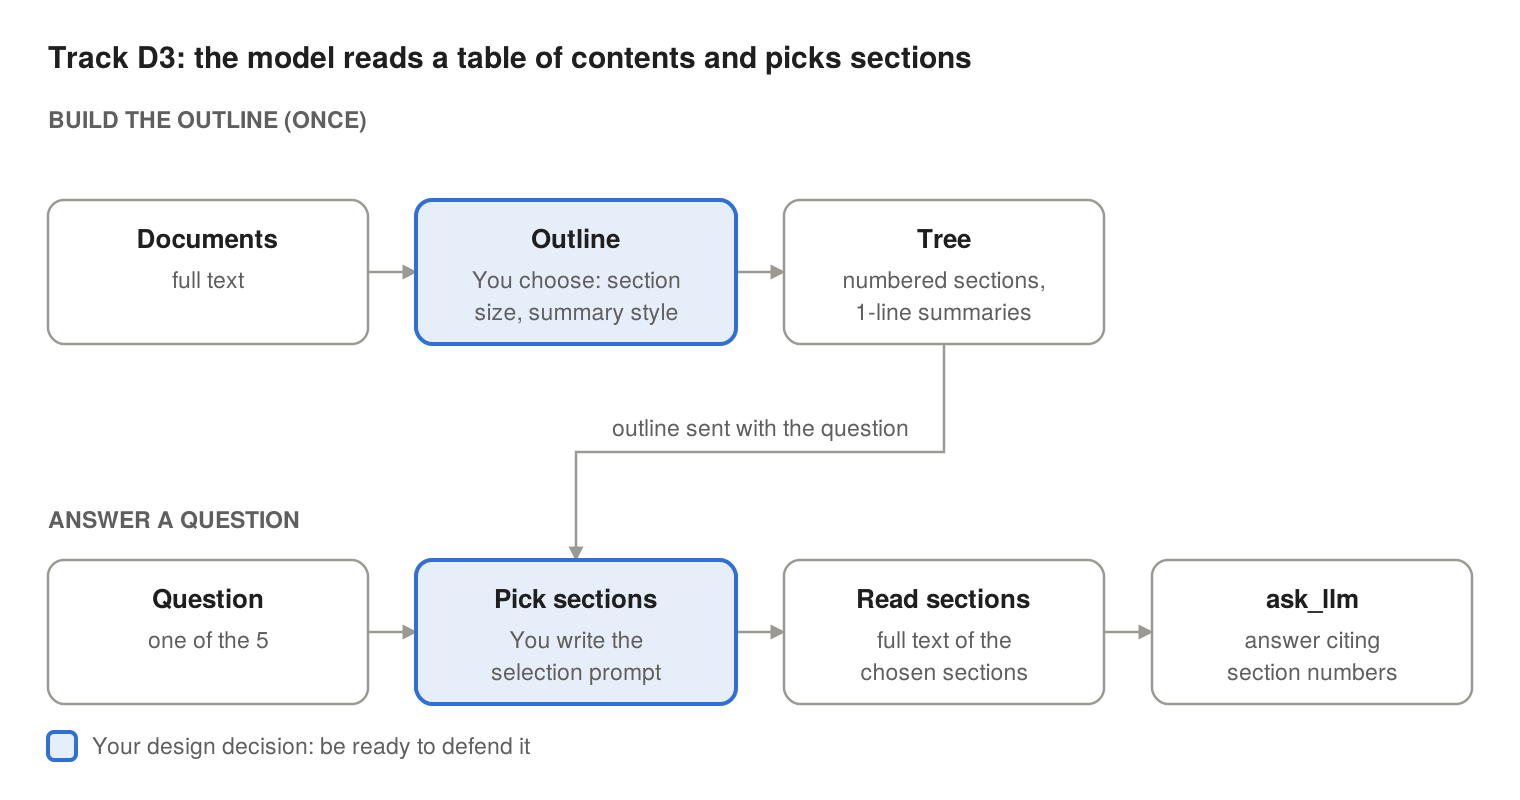

The blue boxes are your design decisions: make them, then direct Claude Code.

**Build**

- Have the LLM outline each document as numbered sections with one-line summaries (and character ranges).
- For each question, show the LLM the outline and let it pick up to 3 sections.
- Answer from only those sections, citing section numbers.

**Discussion point:** What happens with a question that matches no section heading?

In [ ]:
def track_d3(q):
    """Return (answer, evidence) for one question."""
    raise NotImplementedError("Build Track D3 here")

# When it works, run it on the 5 questions (recorded automatically):
# compare({"D3 tree navigation": track_d3})

### Track E: agentic RAG

**Goal:** Let the model decide when to search, what to search for, and when it has enough.

**In one line:** give the model a search tool, and let it decide when to search, what for, and when to stop.

**Example** (illustration):

```
Question: Which team owns the service that failed in last week's incident?
  -> search("last week incident failed service")  finds: "Payments API outage"
  -> search("Payments API owner team")            finds: "Owned by Team Atlas"
  -> answer: Team Atlas, citing both results
```

The second search could only be written after the first one returned.

**Good for:** multi-step and vague questions. **Weak for:** speed and cost; it can loop or stop too early.

[Read more: IBM Agentic RAG recipe](https://github.com/ibm-granite-community/granite-snack-cookbook/blob/main/recipes/AI-Agents/Agentic_RAG.ipynb)

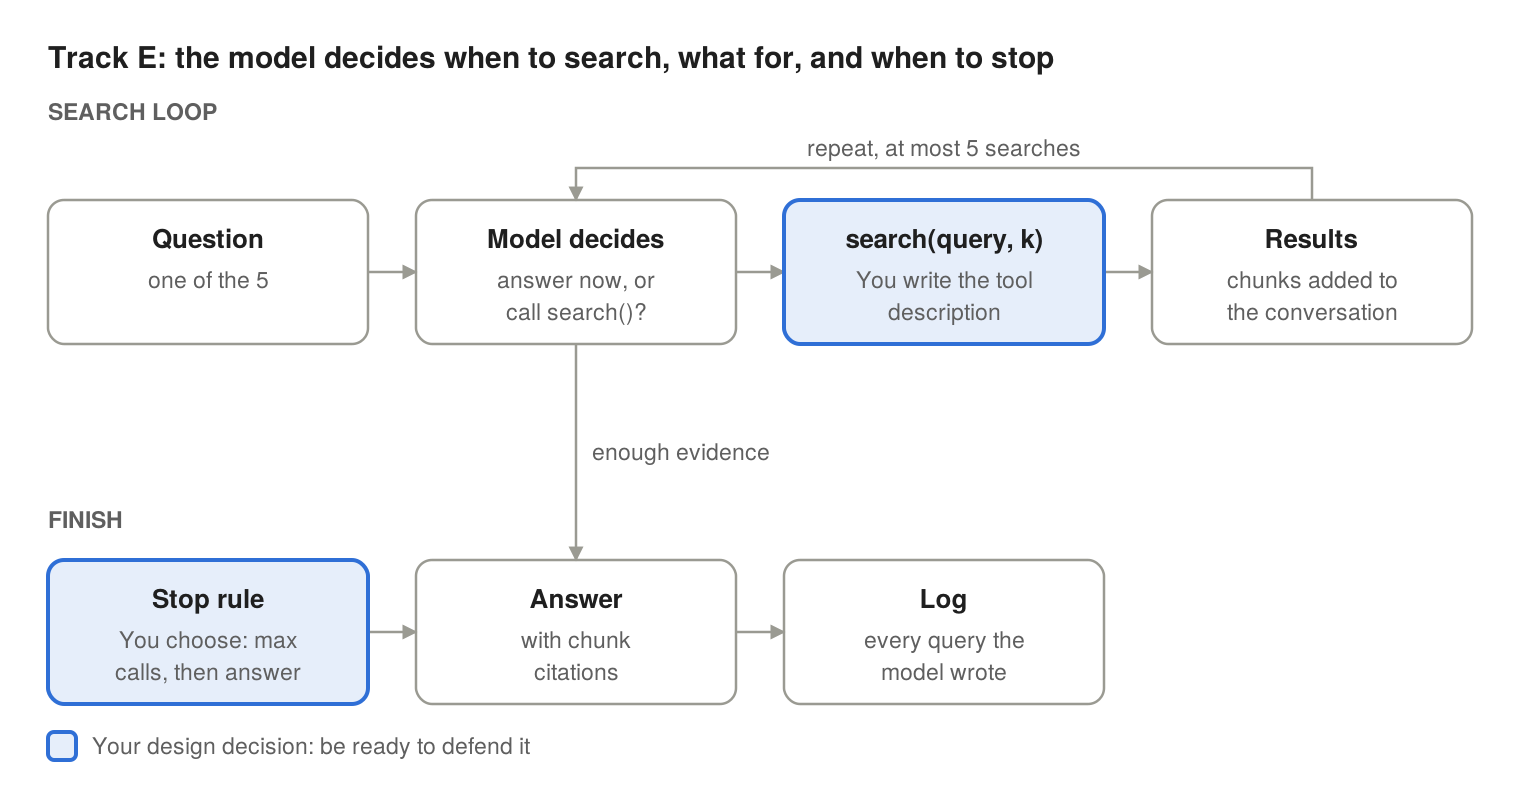

The blue boxes are your design decisions: make them, then direct Claude Code.

**Build**

- Expose `vector_db.similarity_search` as a `search(query, k)` tool using OpenAI-style `tools=[...]`. Use a free model that supports tools.
- Loop: the model may call `search` up to 5 times, then must answer with citations.
- Run Q3 and Q5, and print every query the model writes.

**Discussion point:** What happens when a question needs two facts in sequence, and the second search depends on the first answer?

In [ ]:
def track_e(q):
    """Return (answer, evidence) for one question."""
    raise NotImplementedError("Build Track E here")

# When it works, run it on the 5 questions (recorded automatically):
# compare({"E agentic": track_e})

### GPU extras (Colab T4), if you finish early
- **C2, shared embedding space:** ImageBind plus the Gotham dataset from Elastic's `elasticsearch-labs` repo (`supporting-blog-content/building-multimodal-rag-with-elasticsearch-gotham`). Store the vectors in NumPy or Chroma instead of Elasticsearch, and send the matched evidence to `ask_llm()`.
- **D2, page-image retrieval:** `pip install colpali-engine pdf2image` (plus `apt-get install poppler-utils`). Embed each page image, retrieve the top 2 pages, and call `ask_llm(q, images=pages)`.

## 4. Wrap-up (5 minutes)
Run the next cell. It gathers every run from the warm-up and the tracks into one comparison. Then spend five minutes on judgement: which answers were actually right?

In [ ]:
runs = pd.concat(ALL_RUNS, ignore_index=True).drop_duplicates(["question", "approach"], keep="last")
cost = runs.groupby("approach")["input_tokens"].mean().round(0).rename("avg input tokens per question")
answers = runs.pivot(index="question", columns="approach", values="answer")
display(cost.sort_values().to_frame())
answers        # one row per question, one column per approach you ran

In [ ]:
# Your verdict, in one pass. For each approach: how many of the 5 answers were right?
CORRECT = {approach: None for approach in answers.columns}

# Then three short answers for the class discussion:
BEST_ON_Q3 = ""          # the spread-out answer
BEST_ON_Q4 = ""          # the answer in a chart
I_WOULD_REACH_FOR_RAG_WHEN = ""